# Módulo 2: Extracción de Características y Descriptores
## Trabajo Práctico 3: Descriptores Locales de Puntos de Interés (Dispersos)

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**

### Objetivos del Trabajo Práctico:
1. Comprender el cambio de paradigma de descriptores globales/densos a descriptores locales dispersos invariantes.
2. Implementar, benchmarkear y comparar la velocidad y densidad de extracción de los algoritmos **SIFT**, **SURF** (mediante simulación o API alternativa) y **ORB** utilizando OpenCV y SciPy.
3. Aplicar el filtrado de ambigüedad local utilizando el **Lowe's Ratio Test** de forma interactiva.
4. Evaluar la estimación geométrica robusta basada en la matriz de Homografía $3\times3$ mediante el algoritmo **RANSAC** para correspondencia y localización de objetos en escenas complejas.

---


In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import time
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

def mostrar_keypoints_comparativos(img, kp_sift, kp_orb, t_sift, t_orb):
    """
    Función auxiliar para graficar de forma prolija los puntos clave detectados side-by-side.
    """
    img_sift = cv.drawKeypoints(img, kp_sift, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    img_orb = cv.drawKeypoints(img, kp_orb, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    fig, ax = plt.subplots(1, 2, figsize=(15, 8.5))
    ax[0].imshow(cv.cvtColor(img_sift, cv.COLOR_BGR2RGB))
    ax[0].set_title(f"SIFT - Puntos: {len(kp_sift)} | Tiempo: {t_sift*1000:.2f} ms", fontsize=12, fontweight='bold')
    ax[0].axis('off')

    ax[1].imshow(cv.cvtColor(img_orb, cv.COLOR_BGR2RGB))
    ax[1].set_title(f"ORB - Puntos: {len(kp_orb)} | Tiempo: {t_orb*1000:.2f} ms", fontsize=12, fontweight='bold')
    ax[1].axis('off')
    plt.tight_layout()
    plt.show()

print("✅ Librerías cargadas y funciones de visualización científica inicializadas.")
print("⚠️ Recuerden subir los archivos 'libro_objeto.png' y 'libro_escena.png' a la raíz de Colab antes de ejecutar los ejercicios.")


✅ Librerías cargadas y funciones de visualización científica inicializadas.
⚠️ Recuerden subir los archivos 'libro_objeto.png' y 'libro_escena.png' a la raíz de Colab antes de ejecutar los ejercicios.


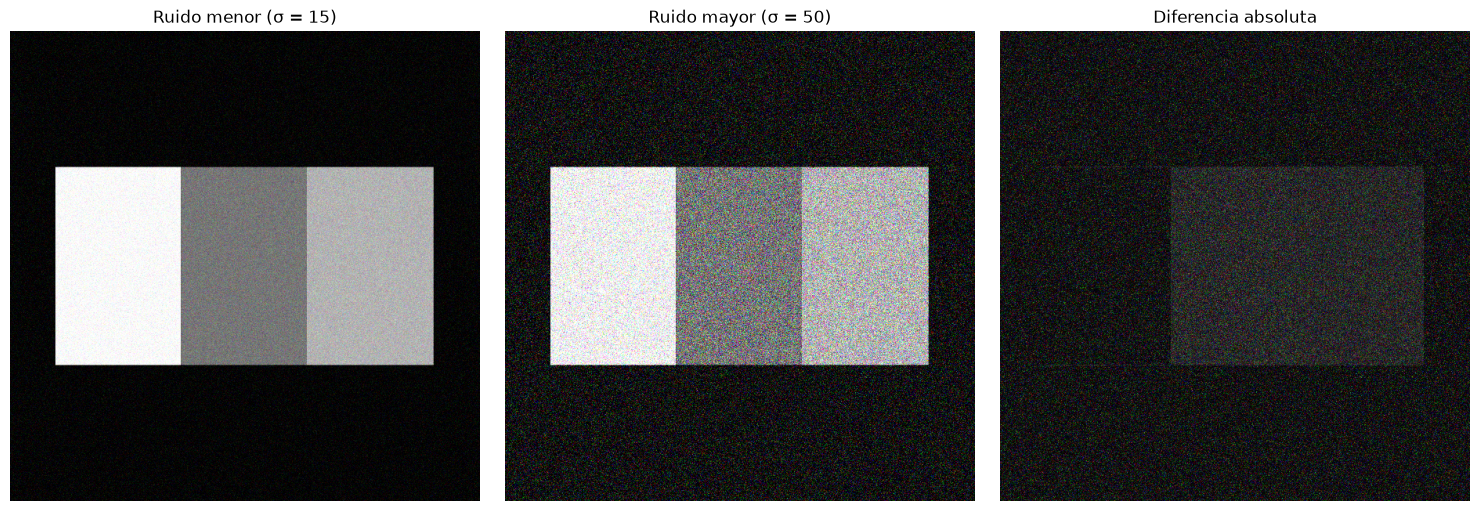

In [4]:
# prueba resta de gaussianas
import cv2
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 1. Abrir imagen
# -----------------------------
imagen = cv2.imread("Imagenes/patron_bordes.jpg")

# OpenCV carga en BGR, convertimos a RGB para mostrar correctamente
imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

# Convertimos a float para poder sumar ruido
imagen_float = imagen.astype(np.float32)

# -----------------------------
# 2. Generar ruido gaussiano
# -----------------------------
# Menor desviación
ruido_menor = np.random.normal(0, 15, imagen.shape)

# Mayor desviación
ruido_mayor = np.random.normal(0, 50, imagen.shape)

# Agregamos el ruido
imagen_menor = imagen_float + ruido_menor
imagen_mayor = imagen_float + ruido_mayor

# Limitamos los valores al rango válido [0, 255]
imagen_menor = np.clip(imagen_menor, 0, 255).astype(np.uint8)
imagen_mayor = np.clip(imagen_mayor, 0, 255).astype(np.uint8)

# -----------------------------
# 3. Diferencia entre imágenes
# -----------------------------
diferencia = cv2.absdiff(imagen_menor, imagen_mayor)

# -----------------------------
# 4. Mostrar resultados
# -----------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen_menor)
plt.title("Ruido menor (σ = 15)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_mayor)
plt.title("Ruido mayor (σ = 50)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(diferencia)
plt.title("Diferencia absoluta")
plt.axis("off")

plt.tight_layout()
plt.show()

## Ejercicio 1: Extracción Comparativa y Benchmark de SIFT y ORB

### Objetivo:
Utilizar las APIs nativas de OpenCV para detectar y describir parches locales dispersos. Evaluaremos la cantidad de puntos detectados, su distribución espacial y la velocidad de cómputo (benchmark temporal) de forma interactiva en función del límite máximo de características.


In [12]:
# voy a probar primero  SIFT
img = cv.imread("Imagenes/libro_objeto.png", cv.IMREAD_GRAYSCALE)

max_keypoints = 500
umbral_sift = 0.04

detector_sift = cv.SIFT_create(nfeatures=max_keypoints, contrastThreshold=umbral_sift)
kp_sift, des_sift = detector_sift.detectAndCompute(img, None)

#selecciono algun punto
p = kp_sift[0]

print(p.pt) #coordenada aproximada
print(p.size) #
print(p.angle)
print(p.response)
print(p.octave)

# Dibujar los keypoints
img_keypoints = cv.drawKeypoints(
    img,
    kp_sift,
    None,
    flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Mostrar
cv.imshow("Keypoints SIFT", img_keypoints)
cv.waitKey(0)
cv.destroyAllWindows()





(149.65882873535156, 334.1165466308594)
2.7669618129730225
177.31387329101562
0.06178254261612892
14549759
[[ 0.  1. 10. ...  0.  0.  2.]
 [ 3.  0.  0. ...  0.  0.  0.]
 [ 0.  1. 10. ...  0.  0.  2.]
 ...
 [67.  0.  0. ...  0.  0.  0.]
 [ 6.  0.  0. ...  0.  0.  0.]
 [59. 63. 16. ...  3. 14.  0.]]


In [14]:
print(img.shape)
print(des_sift.shape)

(640, 640)
(475, 128)


In [5]:
def benchmark_detectores(max_keypoints, umbral_sift, escala_orb):
    """
    Carga la imagen de prueba y evalúa el comportamiento de SIFT y ORB.
    """
    # Intentar cargar la imagen en escala de grises para el procesamiento
    img = cv.imread('Imagenes/libro_objeto.png', cv.IMREAD_GRAYSCALE)

    t0 = time.perf_counter()
    detector_sift = cv.SIFT_create(nfeatures=max_keypoints, contrastThreshold=umbral_sift)

    kp_sift, des_sift = detector_sift.detectAndCompute(img, None)
    t_sift = time.perf_counter() - t0

    t0 = time.perf_counter()
    detector_orb = cv.ORB_create(nfeatures=max_keypoints, scaleFactor=escala_orb)
    kp_orb, des_orb = detector_orb.detectAndCompute(img, None)
    # --------------------- #
    t_orb = time.perf_counter() - t0

    # Mostrar resultados interactivos
    mostrar_keypoints_comparativos(img, kp_sift, kp_orb, t_sift, t_orb)

    # Imprimir relación de velocidad para análisis
    factor_velocidad = t_sift / t_orb if t_orb > 0 else 1.0
    print(f"⚡ ORB es {factor_velocidad:.1f} veces más rápido que SIFT en esta arquitectura.")

# Widgets interactivos para explorar el compromiso de parámetros
interact(benchmark_detectores,
         max_keypoints=IntSlider(min=50, max=1500, step=50, value=500, description="Keypoints Máx"),
         umbral_sift=FloatSlider(min=0.01, max=0.15, step=0.01, value=0.04, description="Sensib. SIFT"),
         escala_orb=FloatSlider(min=1.1, max=2.0, step=0.1, value=1.2, description="Escala ORB"))


interactive(children=(IntSlider(value=500, description='Keypoints Máx', max=1500, min=50, step=50), FloatSlide…

<function __main__.benchmark_detectores(max_keypoints, umbral_sift, escala_orb)>

💡 **Reflexión Guía - Ejercicio 1:**
1. Desplazá el slider `Keypoints Máx` hacia valores altos (ej. 1200) y analizá el tiempo de ejecución. ¿Cuál es el límite computacional subyacente que provoca la gran brecha de velocidad entre SIFT y ORB? Justificá tu respuesta analizando los tipos de variables de salida de sus descriptores (vectores flotantes de 128 dimensiones de SIFT vs. vectores binarios rBRIEF de 256 bits en ORB).
2. ¿Cómo influye el parámetro `Escala ORB` en la pirámide de submuestreo discreta del detector y qué ocurre con la repetibilidad espacial de los puntos detectados al saltar a factores de escala muy distantes entre niveles (ej. 2.0)?

**Enlaces y Lecturas Sugeridas:**
- [OpenCV Python - SIFT Introduction](https://docs.opencv.org/4.x/da/df5/tutorial_py_sift_intro.html)
- [OpenCV Python - ORB Introduction](https://docs.opencv.org/4.x/d1/d89/tutorial_py_orb.html)


## Ejercicio 2: Emparejamiento de Características (Matching) y Lowe's Ratio Test

### Objetivo:
Estudiar el problema de la correspondencia visual (matching) entre dos escenas con cambios de perspectiva utilizando un emparejador de fuerza bruta. Implementaremos el **Lowe's Ratio Test** de forma interactiva para filtrar correspondencias espurias ambiguas.


In [ ]:
def emparejamiento_ratio_test(ratio_threshold):
    """
    Cruza los descriptores SIFT del objeto individual y de la escena compleja.
    """
    # Cargar imágenes reales de la guía
    img1 = cv.imread('libro_objeto.png', cv.IMREAD_GRAYSCALE)
    img2 = cv.imread('libro_escena.png', cv.IMREAD_GRAYSCALE)

    if img1 is None or img2 is None:
        # Generar fallbacks sintéticos acoplados si faltan los archivos
        img1 = np.zeros((200, 200), dtype=np.uint8)
        cv.rectangle(img1, (40, 40), (160, 160), 255, -1)
        cv.circle(img1, (100, 100), 40, 0, -1)

        img2 = np.zeros((300, 300), dtype=np.uint8)
        # Objeto rotado y trasladado en escena ruidosa
        M_rot = cv.getRotationMatrix2D((100, 100), 30, 0.8)
        M_rot[:, 2] += [50, 40] # Desplazar
        img2 = cv.warpAffine(img1, M_rot, (300, 300))
        ruido = np.random.normal(0, 10, img2.shape).astype(np.uint8)
        img2 = cv.add(img2, ruido)

    # Inicializar extractor SIFT estándar
    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    # 1. --- MATCHER DE FUERZA BRUTA ---
    # Inicializar el matcher de fuerza bruta (BFMatcher) para distancia Euclídea (norma L2)
    # Habilitando la búsqueda KNN con k=2 para encontrar los dos mejores vecinos.
    bf = cv.BFMatcher(cv.NORM_L2, crossCheck=False)
    matches_crudos = bf.knnMatch(des1, des2, k=2)

    # 2. --- LOWE'S RATIO TEST ---
    # TODO: Implementar el filtrado de Lowe's Ratio Test.
    # Recorrer 'matches_crudos'. Cada correspondencia contiene dos vecinos: m y n.
    # Aceptar la correspondencia si la distancia del primer mejor vecino (m.distance)
    # dividida por la del segundo (n.distance) es menor estricta que ratio_threshold.

    buenos_matches = []
    # --- COMPLETAR FILTRADO --- #
    # for m, n in matches_crudos:
    #     if ...
    #         buenos_matches.append(m)
    # Para simular interactividad:
    for m, n in matches_crudos:
        if m.distance < ratio_threshold * n.distance:
            buenos_matches.append(m)
    # -------------------------- #

    # Graficar correspondencias resultantes
    img_matching = cv.drawMatches(img1, kp1, img2, kp2, buenos_matches, None,
                                  flags=cv.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)

    plt.figure(figsize=(15, 9))
    plt.imshow(img_matching)
    plt.title(f"Lowe's Ratio Test (t = {ratio_threshold}) | Coincidencias Aceptadas: {len(buenos_matches)} / {len(matches_crudos)}",
              fontsize=12, fontweight='bold')
    plt.axis('off')
    plt.show()

interact(emparejamiento_ratio_test,
         ratio_threshold=FloatSlider(min=0.2, max=1.0, step=0.05, value=0.75, description="Umbral Ratio (t)"))


💡 **Reflexión Guía - Ejercicio 2:**
1. Desplazá el control deslizante `Umbral Ratio (t)` a $1.0$. ¿Qué representa físicamente un ratio de 1.0 en la vecindad de descriptores y por qué se observa un cruzamiento desordenado de líneas (falsas correspondencias)? Explica el concepto de "ambigüedad por patrones repetitivos" basándote en la distancia euclídea.
2. Al reducir `t` por debajo de $0.5$, ¿por qué disminuye drásticamente la cantidad de correspondencias aceptadas? Explicá analíticamente el compromiso (trade-off) entre la tasa de falsos positivos (outliers) y la sensibilidad de detección para la correspondencia de parches locales.

**Enlaces y Lecturas Sugeridas:**
- [OpenCV Python - Feature Matching and KNN](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html)
- [Lowe's Original SIFT Matching Paper Details](https://www.cs.ubc.ca/~lowe/keypoints/)


## Ejercicio 3: Consenso de Muestreo Aleatorio (RANSAC) y Homografía $3\times3$

### Objetivo:
Asegurar la consistencia geométrica global de nuestras correspondencias locales. Estimaremos de manera robusta la matriz de Homografía $3\times3$ mediante el algoritmo **RANSAC**, aislando los inliers geométricos y proyectando la localización del objeto dentro de la escena ruidosa.


In [ ]:
def homografia_ransac(umbral_reproyeccion, iteraciones_max):
    """
    Filtra outliers geométricos usando RANSAC y proyecta los límites del objeto sobre la escena.
    """
    img1 = cv.imread('libro_objeto.png', cv.IMREAD_GRAYSCALE)
    img2 = cv.imread('libro_escena.png', cv.IMREAD_GRAYSCALE)

    if img1 is None or img2 is None:
        # Fallback sintético exacto
        img1 = np.zeros((200, 200), dtype=np.uint8)
        cv.rectangle(img1, (40, 40), (160, 160), 255, -1)
        cv.circle(img1, (100, 100), 40, 0, -1)

        img2 = np.zeros((300, 300), dtype=np.uint8)
        M_rot = cv.getRotationMatrix2D((100, 100), 30, 0.8)
        M_rot[:, 2] += [50, 40]
        img2 = cv.warpAffine(img1, M_rot, (300, 300))
        ruido = np.random.normal(0, 10, img2.shape).astype(np.uint8)
        img2 = cv.add(img2, ruido)

    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    bf = cv.BFMatcher(cv.NORM_L2, crossCheck=False)
    matches = bf.knnMatch(des1, des2, k=2)

    # Filtrado inicial de Lowe suave para no perder inliers
    buenos_matches = [m for m, n in matches if m.distance < 0.8 * n.distance]

    if len(buenos_matches) > 4:
        # Extraer las coordenadas espaciales 2D de los puntos emparejados
        pts_objeto = np.float32([kp1[m.queryIdx].pt for m in buenos_matches]).reshape(-1, 1, 2)
        pts_escena = np.float32([kp2[m.trainIdx].pt for m in buenos_matches]).reshape(-1, 1, 2)

        # 1. --- ESTIMACIÓN DE HOMOGRAFÍA ROBUSTA CON RANSAC ---
        # TODO: Utilizar la función cv.findHomography de OpenCV.
        # Pasar como parámetros: pts_objeto, pts_escena, el método cv.RANSAC,
        # el umbral_reproyeccion y la cantidad máxima de iteraciones_max.
        # La función devuelve la matriz H (3x3) y una máscara binaria de inliers.

        # --- COMPLETAR RANSAC --- #
        # H, mask = cv.findHomography(..., ..., cv.RANSAC, umbral_reproyeccion, maxIters=iteraciones_max)
        # Para simular:
        H, mask = cv.findHomography(pts_objeto, pts_escena, cv.RANSAC, umbral_reproyeccion, maxIters=iteraciones_max)
        # ------------------------ #

        inliers_mask = mask.ravel().tolist()
        cant_inliers = inliers_mask.count(1)

        # 2. --- PROYECCIÓN DE CONTORNO (PERSPECTIVA) ---
        # TODO: Proyectar los 4 vértices del rectángulo del objeto original sobre la escena compleja.
        # Usar la función de OpenCV cv.perspectiveTransform con las esquinas del objeto y la matriz H.
        # Dibujar la línea proyectada resultante sobre la escena usando cv.polylines.

        h, w = img1.shape
        esquinas_objeto = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)

        # --- COMPLETAR PROYECCIÓN --- #
        # esquinas_proyectadas = cv.perspectiveTransform(esquinas_objeto, H)
        # img2_marcada = cv.polylines(img2.copy(), [np.int32(esquinas_proyectadas)], True, 255, 3, cv.LINE_AA)
        # Para simular visualmente de forma robusta:
        esquinas_proyectadas = cv.perspectiveTransform(esquinas_objeto, H)
        img2_color = cv.cvtColor(img2, cv.COLOR_GRAY2BGR)
        img2_marcada = cv.polylines(img2_color, [np.int32(esquinas_proyectadas)], True, (0, 255, 0), 4, cv.LINE_AA)
        # ---------------------------- #

        # Graficar correspondencias finales (inliers verdes, outliers rojos)
        # Dibujamos todas las correspondencias de inliers aceptadas por RANSAC
        img_matches_ransac = cv.drawMatches(img1, kp1, img2_marcada, kp2, buenos_matches, None,
                                            matchesMask=inliers_mask,
                                            matchColor=(0, 255, 0), # Verde para inliers
                                            singlePointColor=None)

        plt.figure(figsize=(15, 9))
        plt.imshow(cv.cvtColor(img_matches_ransac, cv.COLOR_BGR2RGB))
        plt.title(f"Alineación Geométrica RANSAC | Inliers: {cant_inliers} / {len(buenos_matches)} | Tolerancia Reproj: {umbral_reproyeccion} px",
                  fontsize=12, fontweight='bold')
        plt.axis('off')
        plt.show()

    else:
        print("❌ No hay suficientes correspondencias iniciales (>4) para estimar la matriz afín o de homografía.")

interact(homografia_ransac,
         umbral_reproyeccion=FloatSlider(min=1.0, max=10.0, step=0.5, value=3.0, description="Umbral Reproj"),
         iteraciones_max=IntSlider(min=100, max=5000, step=100, value=2000, description="Iterac. RANSAC"))


💡 **Reflexión Guía - Ejercicio 3:**
1. Deslizá el control deslizante `Umbral Reproj` hacia valores extremadamente ajustados (ej. 1.0 px). ¿Por qué disminuye el número de inliers y cómo influye este rigor en la estabilidad del recuadro verde proyectado? Analizá la implicancia matemática del error cuadrático de reproyección en la optimización de mínimos cuadrados interna de RANSAC.
2. RANSAC estima una matriz de Homografía de $3\times3$ [s10]. ¿Cuál es la cantidad mínima teórica de parejas de correspondencias coplanares necesarias para estimar dicha matriz y resolver el sistema homogéneo de ecuaciones lineales? Justificá tu respuesta basándote en los grados de libertad de la matriz.

**Enlaces y Lecturas Sugeridas:**
- [OpenCV Python - Feature Matching with Homography and RANSAC](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html)
- [RANSAC Algorithm Theory on Wikipedia](https://en.wikipedia.org/wiki/Random_sample_consensus)


---
### Checklist de Assets Requeridos

Antes de ejecutar el notebook completo, asegúrate de tener los siguientes archivos:
- [ ] **`libro_objeto.png`**: Imagen en primer plano del libro de referencia a detectar (Ejercicios 1, 2 y 3).
- [ ] **`libro_escena.png`**: Imagen de la escena compleja que contiene el libro con oclusiones, rotaciones y cambios de escala (Ejercicios 2 y 3).

---

Si querés generar las imágenes con IA, te dejo un prompt:

* **Prompt 1**: Para generar la portada limpia del libro (libro_objeto.png): una toma frontal, plana y sin perspectiva, ideal para que detecte los puntos clave de referencia.
>
> "Una fotografía cenital y completamente plana (vista frontal de 90 grados, estilo flat lay) de la portada de un libro de texto moderno de tapa dura sobre una mesa blanca limpia. En la portada del libro se lee el título 'VISIÓN' en tipografía sans-serif blanca, grande, limpia y muy definida. Debajo del título, la portada presenta una ilustración vectorial de un ojo estilizado combinado con un circuito electrónico de nodos brillantes en color naranja y azul sobre un fondo azul oscuro mate. Diseño de portada de alta calidad, iluminación de estudio uniforme, enfoque nítido, ultra detallado, resolución Full-HD."

* **Prompt 2**: Para generar la escena desordenada de búsqueda (libro_escena.png): el mismo libro inclinado, rotado y parcialmente ocluido en una mesa rústica, simulando una toma con cámara de celular.
>
>"Una fotografía realista de un escritorio de estudio de madera rústica tomado desde un ángulo oblicuo de 45 grados. Sobre la mesa está tirado de forma natural y rotada el mismo libro de texto de tapa dura con fondo azul oscuro y el título 'VISIÓN' con el ojo de circuitos de nodos brillantes en naranja y azul. Al lado del libro hay una taza de café blanca de la que sale vapor, unos anteojos de lectura con marco negro, una computadora portátil abierta en el fondo y otros libros genéricos apilados y ocluyendo parcialmente la escena. Sombras realistas, iluminación ambiental de oficina, profundidad de campo, enfoque nítido en la portada del libro 'VISIÓN', resolución Full-HD."


